<a href="https://colab.research.google.com/github/mdkamrulhasan/machine_learning_concepts/blob/master/notebooks/unsupervised/KMeans_Step_by_Step.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Watching k-means Learn: A Step-by-Step Animation

**CIS 635 — Knowledge Discovery & Data Mining**

This notebook shows *how* the k-means algorithm discovers clusters, one step at a time.
We will:

1. Generate a synthetic 2-D dataset of patients (average number of symptoms per week vs. average severity) that has three natural groups.
2. Implement k-means **from scratch** so every intermediate step is visible.
3. Animate the algorithm: random starting centroids, then repeated **assignment** and **update** steps until nothing changes.
4. Replay the run with an interactive slider, try different random starts, and compare with scikit-learn.

### The algorithm in one picture

| Step | What happens |
|---|---|
| **0. Initialize** | Pick $k$ starting centroids at random. |
| **1. Assign** | Give every point to its *nearest* centroid (Euclidean distance). |
| **2. Update** | Move every centroid to the *mean* of the points assigned to it. |
| **3. Repeat** | Go back to step 1 until no point changes cluster (or the centroids stop moving). |

Each assign/update pair can only lower (or keep) the **within-cluster sum of squares**

$$\text{WCSS} = \sum_{j=1}^{k} \sum_{x_i \in C_j} \lVert x_i - \mu_j \rVert^2 ,$$

which is why the algorithm is guaranteed to stop — though not necessarily at the best possible answer.

> **Colab tip:** use *Runtime → Run all*, then scroll to Section 4 to watch the animation. Change the settings in Section 1 and re-run to explore.

## 1. Settings
Change these values and re-run the notebook to explore different scenarios.

In [1]:
# ---------------- Settings you can change ----------------
K          = 3        # number of clusters for k-means
DATA_SEED  = 7        # seed for generating the dataset (keep fixed so the data stays the same)
INIT_SEED  = None     # seed for the random starting centroids; None = a different random start every run
INIT_METHOD = "random_points"   # "random_points" (pick k data points) or "random_uniform" (anywhere in the plot area)
MAX_ITER   = 20       # safety limit on the number of iterations
DELAY      = 1.5      # seconds to pause between animation frames (increase for a slower demo)
SHOW_REGIONS = True   # shade the plane by nearest centroid (the "Voronoi" regions)
# ----------------------------------------------------------

In [2]:
# Imports
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import clear_output, display
import plotly.graph_objects as go

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

# One colour per cluster (colour-blind-friendly palette); grey = not yet assigned
COLORS = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3",
          "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]
UNASSIGNED = "#9AA0A6"

## 2. Generate the data

We draw points from three 2-D Gaussian "blobs" that resemble the reference figure:

| Group | Interpretation | Centre (symptoms, severity) | Shape |
|---|---|---|---|
| A | few symptoms, moderately severe | (2.0, 5.5) | compact |
| B | few-to-moderate symptoms, mild | (3.0, 3.0) | stretched along a diagonal |
| C | many symptoms, severe | (6.0, 6.0) | larger and more spread out |

These "true" group labels are kept only so we can check the result at the end — **k-means never sees them**.

Dataset: 500 points, 2 features


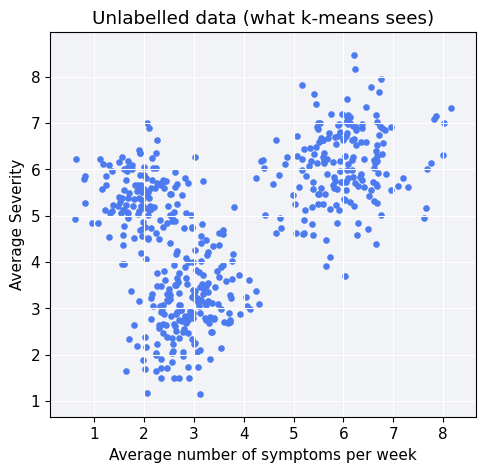

In [3]:
rng = np.random.default_rng(DATA_SEED)

# (mean, covariance, number of points) for each hidden group
groups = [
    ([2.0, 5.5], [[0.35, -0.05], [-0.05, 0.40]], 140),   # A: compact
    ([3.0, 3.0], [[0.35,  0.20], [ 0.20, 0.75]], 180),   # B: diagonal / elongated
    ([6.0, 6.0], [[0.60,  0.10], [ 0.10, 0.80]], 180),   # C: larger spread
]

X_parts, y_parts = [], []
for label, (mean, cov, n) in enumerate(groups):
    X_parts.append(rng.multivariate_normal(mean, cov, size=n))
    y_parts.append(np.full(n, label))

X = np.vstack(X_parts)
y_true = np.concatenate(y_parts)          # hidden labels (NOT used by k-means)

# Keep values in a plausible range (symptoms and severity cannot be negative)
X = np.clip(X, [0.3, 0.3], [9.0, 9.0])

print(f"Dataset: {X.shape[0]} points, {X.shape[1]} features")

# Fixed axis limits used by every plot so frames don't jump around
PAD = 0.5
XLIM = (X[:, 0].min() - PAD, X[:, 0].max() + PAD)
YLIM = (X[:, 1].min() - PAD, X[:, 1].max() + PAD)
XLABEL, YLABEL = "Average number of symptoms per week", "Average Severity"

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(X[:, 0], X[:, 1], s=14, color="#4C7BF0")
ax.set(xlim=XLIM, ylim=YLIM, xlabel=XLABEL, ylabel=YLABEL, title="Unlabelled data (what k-means sees)")
ax.set_facecolor("#F2F3F7"); ax.grid(color="white")
plt.show()

## 3. k-means from scratch (recording every step)

Rather than calling a library, we write the two steps ourselves and **save a snapshot after each one**.
Each snapshot stores the centroids, the cluster assignments, the WCSS, and a short caption.
The animation in Section 4 simply plays these snapshots back.

In [4]:
def init_centroids(X, k, method="random_points", seed=None):
    # Choose k random starting centroids.
    r = np.random.default_rng(seed)
    if method == "random_points":
        # Forgy initialization: k distinct data points chosen at random
        return X[r.choice(len(X), size=k, replace=False)].copy()
    elif method == "random_uniform":
        # Anywhere inside the bounding box of the data (can produce empty clusters)
        lo, hi = X.min(axis=0), X.max(axis=0)
        return r.uniform(lo, hi, size=(k, X.shape[1]))
    raise ValueError("method must be 'random_points' or 'random_uniform'")


def assign_step(X, centroids):
    # Distance from every point to every centroid -> index of the nearest centroid.
    d = np.linalg.norm(X[:, None, :] - centroids[None, :, :], axis=2)   # shape (n, k)
    return d.argmin(axis=1)


def update_step(X, labels, centroids):
    # Move each centroid to the mean of its points (an empty cluster keeps its old position).
    new = centroids.copy()
    for j in range(len(centroids)):
        members = X[labels == j]
        if len(members) > 0:
            new[j] = members.mean(axis=0)
    return new


def wcss(X, labels, centroids):
    # Within-cluster sum of squared distances to the assigned centroid.
    return float(((X - centroids[labels]) ** 2).sum())


def kmeans_with_history(X, k, init_method="random_points", seed=None, max_iter=20, tol=1e-6):
    # Run k-means and return a list of snapshots, one per step.
    centroids = init_centroids(X, k, init_method, seed)
    history = [dict(phase="init", iteration=0, centroids=centroids.copy(), labels=None,
                    prev_centroids=None, wcss=None, n_changed=None,
                    caption="Step 0: choose k random starting centroids")]
    labels = None
    for it in range(1, max_iter + 1):
        # ---- Assignment step ----
        new_labels = assign_step(X, centroids)
        n_changed = len(X) if labels is None else int((new_labels != labels).sum())
        labels = new_labels
        history.append(dict(phase="assign", iteration=it, centroids=centroids.copy(),
                            labels=labels.copy(), prev_centroids=None,
                            wcss=wcss(X, labels, centroids), n_changed=n_changed,
                            caption=f"Iteration {it} - ASSIGN: each point joins its nearest centroid "
                                    f"({n_changed} points changed)"))
        if it > 1 and n_changed == 0:
            history[-1]["caption"] = f"Iteration {it} - ASSIGN: no point changed cluster -> converged!"
            history[-1]["phase"] = "converged"
            break

        # ---- Update step ----
        new_centroids = update_step(X, labels, centroids)
        shift = float(np.linalg.norm(new_centroids - centroids, axis=1).max())
        history.append(dict(phase="update", iteration=it, centroids=new_centroids.copy(),
                            labels=labels.copy(), prev_centroids=centroids.copy(),
                            wcss=wcss(X, labels, new_centroids), n_changed=n_changed,
                            caption=f"Iteration {it} - UPDATE: move each centroid to the mean "
                                    f"of its points (largest move {shift:.2f})"))
        centroids = new_centroids
        if shift < tol:
            history.append(dict(phase="converged", iteration=it, centroids=centroids.copy(),
                                labels=labels.copy(), prev_centroids=None,
                                wcss=wcss(X, labels, centroids), n_changed=0,
                                caption=f"Iteration {it}: centroids stopped moving -> converged!"))
            break
    return history


history = kmeans_with_history(X, K, INIT_METHOD, INIT_SEED, MAX_ITER)
n_iter = history[-1]["iteration"]
print(f"k = {K}: {len(history)} snapshots recorded, converged after {n_iter} iterations")
print(f"Final WCSS = {history[-1]['wcss']:.2f}")

k = 3: 16 snapshots recorded, converged after 8 iterations
Final WCSS = 470.59


## 4. Watch k-means learn ▶

Run the cell below. The figure redraws itself every `DELAY` seconds:

* **Left panel — the data.**
  * Grey points have not been assigned yet.
  * **★ stars** are the centroids; the shaded background shows which centroid is closest to each spot on the plane (its *region*).
  * In an **ASSIGN** frame the points take the colour of their nearest centroid.
  * In an **UPDATE** frame an arrow shows each centroid moving from its old position (hollow circle) to the mean of its points; faint dotted lines trace the path each centroid has taken so far.
* **Right panel — the objective.** WCSS after each step. It never goes up, and it flattens out as the algorithm converges.

Want to see it again with a different random start? Just re-run the cell in Section 3 and then this one (with `INIT_SEED = None`).

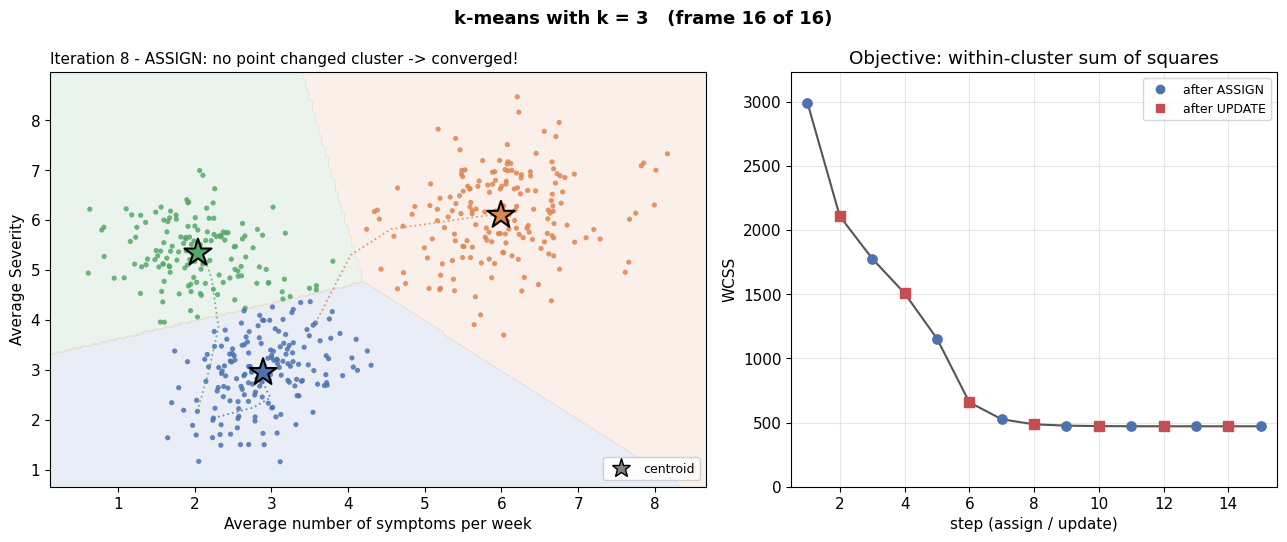

In [5]:
def nearest_region_grid(centroids, res=200):
    # Label every point of a fine grid by its nearest centroid (for background shading).
    gx, gy = np.meshgrid(np.linspace(*XLIM, res), np.linspace(*YLIM, res))
    grid = np.c_[gx.ravel(), gy.ravel()]
    return gx, gy, assign_step(grid, centroids).reshape(gx.shape)


def draw_frame(history, step, axes, show_regions=SHOW_REGIONS):
    # Draw snapshot number `step` on the two axes (data panel, WCSS panel).
    ax, ax2 = axes
    ax.clear(); ax2.clear()
    snap = history[step]
    C, labels = snap["centroids"], snap["labels"]
    k = len(C)
    cols = np.array(COLORS[:k])

    # Background regions (nearest-centroid zones)
    if show_regions:
        gx, gy, zone = nearest_region_grid(C)
        ax.contourf(gx, gy, zone, levels=np.arange(-0.5, k), colors=cols, alpha=0.12)

    # Points
    point_colors = UNASSIGNED if labels is None else cols[labels]
    ax.scatter(X[:, 0], X[:, 1], s=14, c=point_colors, edgecolors="none", alpha=0.85)

    # Path each centroid has travelled so far (dotted line through its earlier positions)
    path = np.array([h["centroids"] for h in history[:step + 1]])   # (steps, k, 2)
    for j in range(k):
        ax.plot(path[:, j, 0], path[:, j, 1], ":", color=cols[j], lw=1.3, alpha=0.8)

    # On an UPDATE step: hollow marker at the old position + arrow to the new position
    if snap["prev_centroids"] is not None:
        P = snap["prev_centroids"]
        ax.scatter(P[:, 0], P[:, 1], s=180, facecolors="none", edgecolors=cols, linewidths=2)
        for j in range(k):
            ax.annotate("", xy=C[j], xytext=P[j],
                        arrowprops=dict(arrowstyle="-|>", color="black", lw=2, mutation_scale=18))

    # Centroids (stars)
    ax.scatter(C[:, 0], C[:, 1], s=420, marker="*", c=cols, edgecolors="black", linewidths=1.5, zorder=5)

    ax.set(xlim=XLIM, ylim=YLIM, xlabel=XLABEL, ylabel=YLABEL)
    ax.set_title(snap["caption"], fontsize=11, loc="left", wrap=True)
    legend = [Line2D([], [], marker="*", ls="", color="grey", markeredgecolor="black", ms=14, label="centroid")]
    if snap["prev_centroids"] is not None:
        legend.append(Line2D([], [], marker="o", ls="", markerfacecolor="none", markeredgecolor="grey",
                             ms=10, mew=2, label="previous position"))
    ax.legend(handles=legend, loc="lower right", fontsize=9, framealpha=0.9)

    # WCSS panel: all steps so far, with assign/update steps marked differently
    done = [h for h in history[1:step + 1] if h["wcss"] is not None]
    xs = list(range(1, len(done) + 1))
    ax2.plot(xs, [h["wcss"] for h in done], "-", color="#555", lw=1.5)
    for x_, h in zip(xs, done):
        m = "s" if h["phase"] == "update" else "o"
        ax2.scatter(x_, h["wcss"], marker=m, s=45, color="#C44E52" if h["phase"] == "update" else "#4C72B0", zorder=3)
    all_w = [h["wcss"] for h in history if h["wcss"] is not None]
    ax2.set_xlim(0.5, max(len(all_w), 2) + 0.5)
    ax2.set_ylim(0, max(all_w) * 1.08)
    ax2.set(xlabel="step (assign / update)", ylabel="WCSS", title="Objective: within-cluster sum of squares")
    ax2.legend(handles=[Line2D([], [], marker="o", ls="", color="#4C72B0", label="after ASSIGN"),
                        Line2D([], [], marker="s", ls="", color="#C44E52", label="after UPDATE")],
               fontsize=9, loc="upper right")
    ax2.grid(alpha=0.3)


def animate(history, delay=DELAY):
    # Play the snapshots one by one, redrawing the figure in place.
    for step in range(len(history)):
        fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.35, 1]})
        draw_frame(history, step, axes)
        fig.suptitle(f"k-means with k = {len(history[0]['centroids'])}   "
                     f"(frame {step + 1} of {len(history)})", fontsize=13, fontweight="bold")
        fig.tight_layout()
        clear_output(wait=True)       # replace the previous frame instead of stacking figures
        display(fig)
        plt.close(fig)
        # pause longer on the very first and the final frame so they can be discussed
        time.sleep(delay * (2 if step in (0, len(history) - 1) else 1))


animate(history)

### What to notice

* **Step 0** — the random starting centroids are usually poorly placed (sometimes two land inside the same blob).
* **The first few iterations** produce the biggest changes: many points switch cluster and the centroids take long strides.
* **Later iterations** only move points near the boundaries between regions; the arrows get shorter and WCSS flattens.
* **Convergence** — the algorithm stops when an assignment step changes nothing. Because the centroids then don't move either, running further would change nothing.
* The boundaries between coloured regions are always **straight lines** (perpendicular bisectors between centroids). That is why k-means prefers round, similar-sized clusters and struggles with elongated or very unequal groups.

## 5. Replay with a slider (interactive Plotly version)

The live animation above can't be rewound. The figure below contains the **same run** as an interactive animation: press **▶ Play**, or drag the slider to jump to any step and talk through it. Hover over a centroid to see its coordinates.

In [6]:
def plotly_replay(history, frame_ms=None):
    frame_ms = int((frame_ms or DELAY * 1000))
    k = len(history[0]["centroids"])
    cols = np.array(COLORS[:k])

    def traces_for(snap, step):
        C, labels = snap["centroids"], snap["labels"]
        pc = [UNASSIGNED] * len(X) if labels is None else cols[labels].tolist()
        path = np.array([h["centroids"] for h in history[:step + 1]])
        tr = [go.Scatter(x=X[:, 0], y=X[:, 1], mode="markers",
                         marker=dict(size=6, color=pc, opacity=0.8), name="points",
                         hoverinfo="skip", showlegend=False)]
        # centroid paths (one trace per cluster, always present so the frame structure is fixed)
        for j in range(k):
            tr.append(go.Scatter(x=path[:, j, 0], y=path[:, j, 1], mode="lines",
                                 line=dict(color=cols[j], dash="dot", width=2),
                                 hoverinfo="skip", showlegend=False))
        # previous positions (empty unless this is an UPDATE step)
        P = snap["prev_centroids"]
        tr.append(go.Scatter(x=[] if P is None else P[:, 0], y=[] if P is None else P[:, 1],
                             mode="markers", name="previous position",
                             marker=dict(size=16, color="rgba(0,0,0,0)", line=dict(width=2.5, color=cols.tolist()))))
        tr.append(go.Scatter(x=C[:, 0], y=C[:, 1], mode="markers", name="centroid",
                             marker=dict(symbol="star", size=24, color=cols.tolist(),
                                         line=dict(width=1.5, color="black")),
                             text=[f"cluster {j + 1}" for j in range(k)],
                             hovertemplate="%{text}<br>(%{x:.2f}, %{y:.2f})<extra></extra>"))
        return tr

    frames = [go.Frame(data=traces_for(h, i), name=str(i),
                       layout=go.Layout(title_text=f"Frame {i + 1}/{len(history)} - {h['caption']}"))
              for i, h in enumerate(history)]

    fig = go.Figure(data=frames[0].data, frames=frames)
    fig.update_layout(
        title=dict(text=f"Frame 1/{len(history)} - {history[0]['caption']}", font=dict(size=14)),
        xaxis=dict(range=list(XLIM), title=XLABEL),
        yaxis=dict(range=list(YLIM), title=YLABEL),
        width=820, height=640, template="plotly_white",
        legend=dict(orientation="h", y=-0.22),
        updatemenus=[dict(type="buttons", direction="left", x=0.0, y=1.12, xanchor="left",
                          buttons=[dict(label="▶ Play", method="animate",
                                        args=[None, dict(frame=dict(duration=frame_ms, redraw=True),
                                                         transition=dict(duration=300), fromcurrent=True)]),
                                   dict(label="❚❚ Pause", method="animate",
                                        args=[[None], dict(frame=dict(duration=0, redraw=False),
                                                           mode="immediate")])])],
        sliders=[dict(active=0, y=-0.05, currentvalue=dict(prefix="Frame: "),
                      steps=[dict(label=str(i + 1), method="animate",
                                  args=[[str(i)], dict(frame=dict(duration=0, redraw=True), mode="immediate")])
                             for i in range(len(history))])],
    )
    return fig

plotly_replay(history).show()

## 6. Different random starts → different answers?

k-means only finds a **local** minimum of WCSS: the result depends on where the centroids start.
Below we run the algorithm from 8 different random starts and show the final clustering of each.
Look for runs that split one natural group in two and merge two others — and compare their final WCSS.

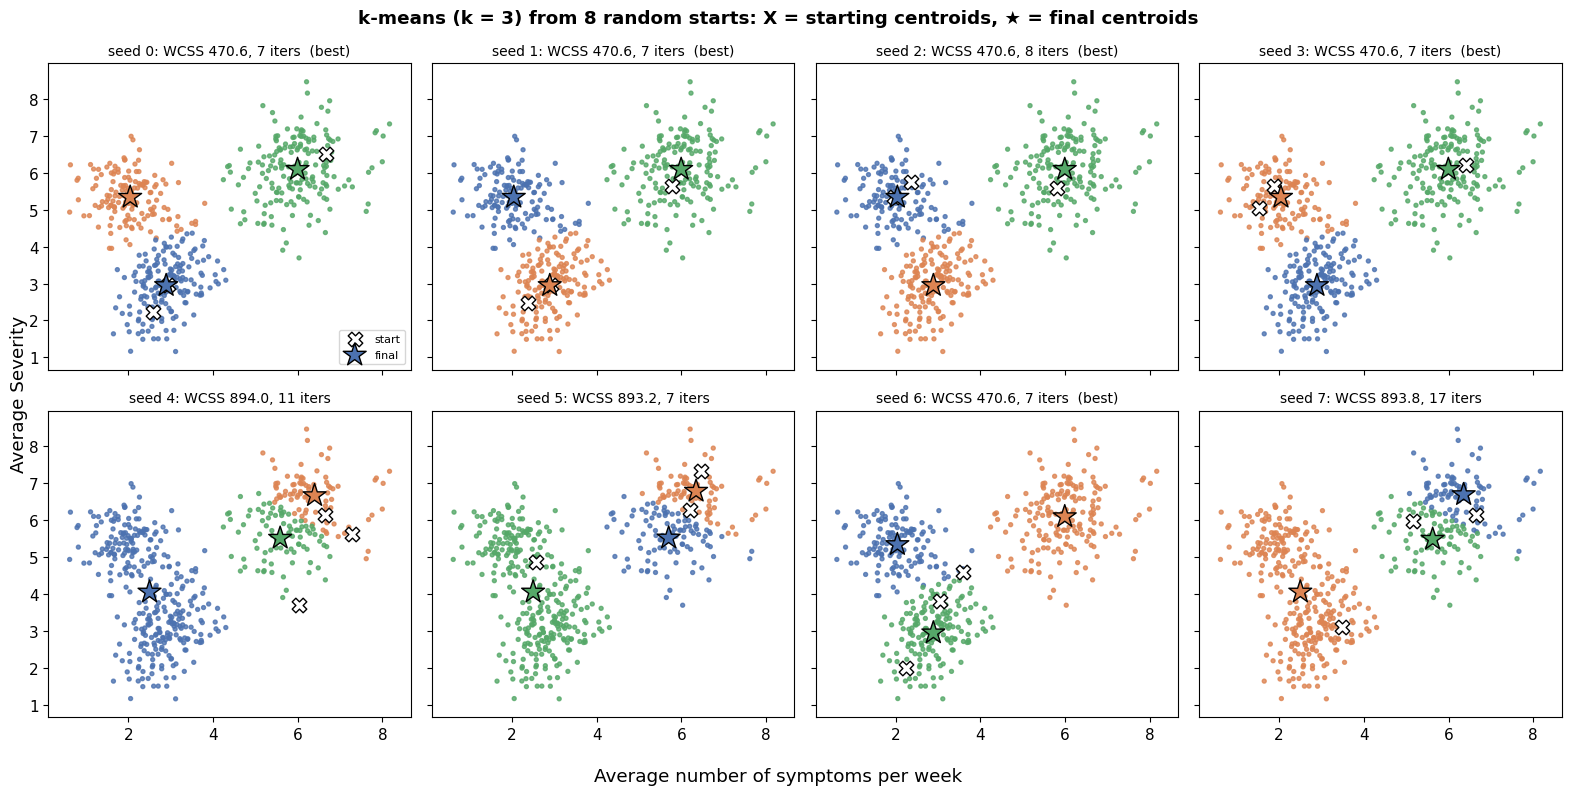

Final WCSS by seed: {0: 470.6, 1: 470.6, 2: 470.6, 3: 470.6, 4: 894.0, 5: 893.2, 6: 470.6, 7: 893.8}


In [7]:
seeds = range(8)
runs = [kmeans_with_history(X, K, INIT_METHOD, s, MAX_ITER) for s in seeds]

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True)
best = min(r[-1]["wcss"] for r in runs)
for ax, s, run in zip(axes.ravel(), seeds, runs):
    final, start = run[-1], run[0]
    cols = np.array(COLORS[:K])
    ax.scatter(X[:, 0], X[:, 1], s=8, c=cols[final["labels"]], alpha=0.8)
    ax.scatter(start["centroids"][:, 0], start["centroids"][:, 1], marker="X", s=110,
               c="white", edgecolors="black", label="start")
    ax.scatter(final["centroids"][:, 0], final["centroids"][:, 1], marker="*", s=300,
               c=cols, edgecolors="black", label="final")
    tag = "  (best)" if np.isclose(final["wcss"], best) else ""
    ax.set_title(f"seed {s}: WCSS {final['wcss']:.1f}, {final['iteration']} iters{tag}", fontsize=10)
    ax.set(xlim=XLIM, ylim=YLIM)
axes[0, 0].legend(fontsize=8, loc="lower right")
fig.supxlabel(XLABEL); fig.supylabel(YLABEL)
fig.suptitle(f"k-means (k = {K}) from 8 random starts: X = starting centroids, ★ = final centroids", fontweight="bold")
fig.tight_layout()
plt.show()

print("Final WCSS by seed:", {s: round(r[-1]["wcss"], 1) for s, r in zip(seeds, runs)})

**Takeaway.** This is why practical implementations (e.g. scikit-learn's `KMeans`) use

* **smarter initialization** — *k-means++* spreads the starting centroids out, and
* **several restarts** (`n_init`) — run k-means many times and keep the run with the lowest WCSS.

Try changing `INIT_METHOD = "random_uniform"` in Section 1: starting centroids placed anywhere in the plot area are more likely to give poor solutions or even an **empty cluster**.

## 7. Sanity check against scikit-learn

Our from-scratch version should agree with the library. We also compare both with the hidden "true" groups using the **Adjusted Rand Index** (ARI: 1 = identical grouping, 0 = no better than chance).

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

best_run = min(runs, key=lambda r: r[-1]["wcss"])
km = KMeans(n_clusters=K, init="k-means++", n_init=10, random_state=0).fit(X)

print(f"Our k-means (best of 8 random starts): WCSS = {best_run[-1]['wcss']:.2f}")
print(f"scikit-learn KMeans (k-means++, n_init=10): WCSS = {km.inertia_:.2f}")
print(f"Agreement between the two clusterings (ARI): {adjusted_rand_score(best_run[-1]['labels'], km.labels_):.3f}")
print(f"Our result vs. hidden true groups (ARI):     {adjusted_rand_score(y_true, best_run[-1]['labels']):.3f}")

Our k-means (best of 8 random starts): WCSS = 470.59
scikit-learn KMeans (k-means++, n_init=10): WCSS = 470.69
Agreement between the two clusterings (ARI): 1.000
Our result vs. hidden true groups (ARI):     0.934


## 8. Try it yourself

1. **Change k.** Set `K = 2`, `4`, and `5` in Section 1 and re-run. Which groups get merged or split? Does a lower WCSS always mean a "better" clustering?
2. **Bad starts.** Find a value of `INIT_SEED` that converges to a poor solution. How many iterations did it take compared with a good start?
3. **Scaling matters.** Multiply the severity column by 10 (`X[:, 1] *= 10`) right after the data are generated and re-run. What happens to the clusters, and why? (Hint: Euclidean distance.)
4. **Shape matters.** Make group B much more elongated (e.g. covariance `[[0.2, 0.6], [0.6, 2.5]]`). Can k-means still recover it? Think about the straight-line boundaries in the animation.